# Chapter 8: Learning Signal and Ignoring Noise
## Introduction to Regularization and Batching

**Book:** Grokking Deep Learning
**Author:** Andrew W. Trask

### Learning Objectives
- Understand memorization and generalization.
- Identify overfitting in neural networks.
- Understand early stopping as a regularization technique.
- Explain dropout and how it works.
- Understand batch gradient descent.
- Explore digit classification using the MNIST dataset.

## 1. Three-Layer Network on MNIST

MNIST merupakan dataset yang berisi gambar angka tulisan tangan
dari 0 sampai 9. Setiap gambar memiliki ukuran 28 × 28 piksel.

Pada chapter ini, jaringan saraf tiga layer digunakan untuk
mempelajari hubungan antara gambar dan label angka yang sesuai.

Struktur jaringan terdiri dari:
- Input layer: menerima nilai piksel gambar.
- Hidden layer: mempelajari representasi dan pola dari gambar.
- Output layer: menghasilkan prediksi untuk sepuluh kelas angka.

Tujuan eksperimen ini bukan hanya memperoleh prediksi yang benar
pada data training, tetapi juga memahami apakah jaringan mampu
memprediksi gambar baru yang belum pernah dilihat.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


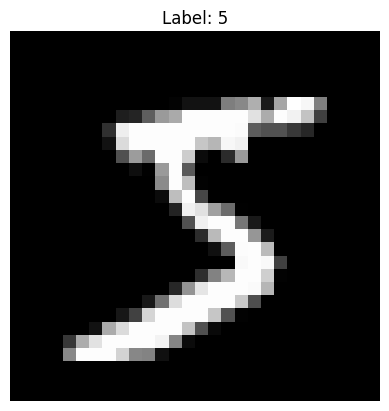

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Memuat dataset MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

# Menampilkan salah satu gambar
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

## 2. Well, That Was Easy

Jaringan saraf dapat mempelajari data training dengan memperbarui
weight berdasarkan perbedaan antara prediksi dan label sebenarnya.

Jika proses training dilakukan berulang kali, jaringan dapat
mencapai akurasi yang sangat tinggi, bahkan memprediksi seluruh
contoh pada data training dengan benar.

Namun, keberhasilan tersebut belum tentu menunjukkan bahwa model
benar-benar memahami pola yang berlaku secara umum.

Model perlu diuji menggunakan data yang tidak digunakan saat
training untuk mengetahui kemampuannya menghadapi contoh baru.

## 3. Memorization vs. Generalization

**Memorization** terjadi ketika model mempelajari detail dari
data training, termasuk detail yang tidak relevan untuk prediksi.

**Generalization** adalah kemampuan model menggunakan pola yang
dipelajari untuk menghasilkan prediksi yang baik pada data baru.

Model yang hanya menghafal data training dapat memperoleh hasil
yang sangat baik pada data tersebut, tetapi belum tentu berhasil
pada data testing.

Oleh karena itu, performa training dan testing perlu dibandingkan
untuk menilai kemampuan generalisasi model.

## 4. Overfitting in Neural Networks

Overfitting terjadi ketika model terlalu menyesuaikan diri dengan
data training sehingga ikut mempelajari noise atau detail yang
tidak mewakili pola umum.

Neural network yang memiliki banyak weight dan kapasitas representasi
besar dapat lebih mudah mempelajari detail spesifik pada training
data jika tidak dikendalikan dengan baik.

Tanda yang dapat menunjukkan overfitting adalah performa training
yang sangat baik, tetapi performa validation atau testing jauh
lebih buruk.

Salah satu cara mengurangi overfitting adalah menggunakan
regularization.

## 5. Where Overfitting Comes From

Overfitting dapat terjadi karena model mempelajari detail yang
kebetulan muncul pada data training, bukan hanya informasi yang
penting untuk tugas prediksi.

Dalam klasifikasi gambar, misalnya, bentuk objek dapat menjadi
signal yang berguna, sedangkan latar belakang atau detail tertentu
yang tidak konsisten dapat menjadi noise.

Jika model terlalu berfokus pada noise, perubahan kecil pada gambar
baru dapat menyebabkan prediksi menjadi salah.

Karena itu, proses training perlu mendorong model mempelajari
signal yang relevan dan mengurangi ketergantungan pada noise.

## 6. The Simplest Regularization: Early Stopping

Early stopping adalah teknik regularization dengan menghentikan
training sebelum model terlalu jauh mempelajari detail spesifik
pada data training.

Untuk menentukan kapan training perlu dihentikan, performa model
dapat dipantau menggunakan validation set.

Jika performa validation mulai memburuk sementara performa training
terus membaik, hal tersebut dapat menjadi tanda overfitting.

Validation set digunakan untuk membantu menentukan waktu berhenti,
sedangkan test set sebaiknya disimpan untuk evaluasi akhir.

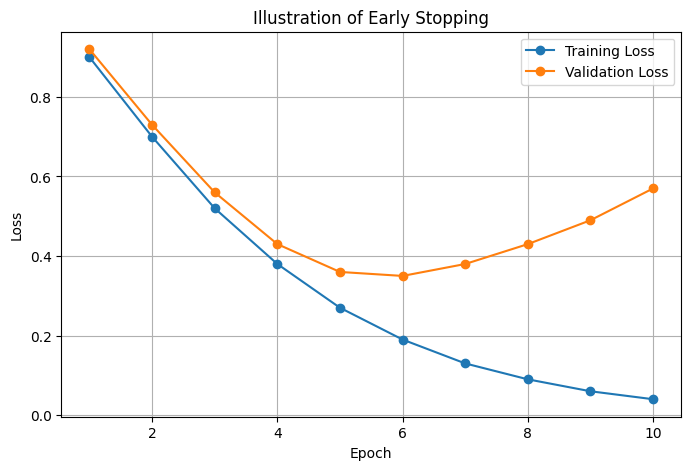

Epoch with lowest validation loss: 6


In [2]:
# Contoh simulasi nilai loss selama training
epochs = np.arange(1, 11)

train_loss = [0.90, 0.70, 0.52, 0.38, 0.27,
              0.19, 0.13, 0.09, 0.06, 0.04]

val_loss = [0.92, 0.73, 0.56, 0.43, 0.36,
            0.35, 0.38, 0.43, 0.49, 0.57]

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Illustration of Early Stopping")
plt.legend()
plt.grid(True)
plt.show()

best_epoch = int(np.argmin(val_loss) + 1)
print("Epoch with lowest validation loss:", best_epoch)

## 7. Industry Standard Regularization: Dropout

Dropout merupakan teknik regularization yang menonaktifkan
sebagian neuron secara acak selama training.

Neuron yang dinonaktifkan tidak memberikan kontribusi pada
forward propagation untuk langkah training tersebut. Jalur
pembelajaran yang berbeda dapat terbentuk dari kombinasi neuron
yang aktif.

Dalam contoh pada buku, dropout diterapkan pada hidden layer
dengan menonaktifkan sekitar 50% neuron secara acak.

Teknik ini membantu mengurangi ketergantungan model terhadap
neuron tertentu dan dapat mengurangi overfitting.

## 8. Why Dropout Works: Ensembling Works

Dropout dapat dipahami sebagai proses melatih berbagai subnetworks
yang terbentuk dari jaringan utama melalui kombinasi neuron aktif
yang berbeda.

Setiap subnetwork dapat mempelajari pola yang sedikit berbeda.
Ketika dropout digunakan, jaringan tidak selalu mengandalkan
kombinasi neuron yang sama pada setiap langkah training.

Gagasan ini berkaitan dengan ensembling, yaitu menggabungkan
kontribusi dari beberapa model atau variasi model untuk memperoleh
prediksi yang lebih kuat.

Dropout bukan berarti beberapa model terpisah selalu dibuat dan
disimpan secara eksplisit. Neuron yang dinonaktifkan secara acak
membantu membentuk variasi subnetwork selama training.

In [3]:
# Contoh hidden layer dengan 8 neuron
np.random.seed(1)

layer_1 = np.array([[0.2, 0.8, 0.5, 0.9,
                     0.4, 0.7, 0.3, 0.6]])

# Membuat dropout mask: 0 berarti nonaktif, 1 berarti aktif
dropout_mask = np.random.randint(2, size=layer_1.shape)

# Menonaktifkan neuron secara acak dan menyesuaikan skala
layer_1_dropout = layer_1 * dropout_mask * 2

print("Original hidden layer:")
print(layer_1)

print("\nDropout mask:")
print(dropout_mask)

print("\nHidden layer after dropout:")
print(layer_1_dropout)

Original hidden layer:
[[0.2 0.8 0.5 0.9 0.4 0.7 0.3 0.6]]

Dropout mask:
[[1 1 0 0 1 1 1 1]]

Hidden layer after dropout:
[[0.4 1.6 0.  0.  0.8 1.4 0.6 1.2]]


## 9. Dropout in Code

Dropout perlu diterapkan secara konsisten pada proses training.
Pada contoh jaringan MNIST di buku, dropout mask diterapkan pada
hidden layer setelah aktivasi ReLU.

Selain memengaruhi aktivasi hidden layer, mask yang sama juga
digunakan pada delta hidden layer ketika backpropagation dilakukan.
Dengan begitu, neuron yang dinonaktifkan tidak ikut memberikan
kontribusi pada pembaruan weight dalam langkah tersebut.

Saat evaluasi, dropout tidak diterapkan dengan cara yang sama
seperti saat training. Skala aktivasi perlu tetap konsisten antara
training dan evaluasi.

## 10. Dropout Evaluated on MNIST

Untuk mengevaluasi dropout, hasil model dapat dibandingkan dengan
model yang dilatih tanpa dropout.

Perbandingan perlu memperhatikan setidaknya dua hal:

- Performa pada data training.
- Performa pada data testing yang tidak digunakan selama training.

Model dengan dropout mungkin tidak menghafal data training secepat
model tanpa regularization. Namun, tujuan utamanya adalah membantu
model mempelajari pola yang lebih mampu diterapkan pada data baru.

Hasil eksperimen dapat berbeda bergantung pada jumlah data,
arsitektur, inisialisasi weight, dan pengaturan training.

## 11. Batch Gradient Descent

Batch gradient descent merupakan pendekatan pembelajaran yang
menggunakan kumpulan contoh data untuk menghitung pembaruan weight.

Dalam pembelajaran berbasis satu contoh, weight diperbarui setelah
setiap contoh diproses. Pada batch gradient descent, kontribusi
error atau gradient dari beberapa contoh digabungkan sebelum
weight diperbarui.

Secara umum, terdapat tiga pendekatan:

- Full-batch gradient descent: menggunakan seluruh data training
  untuk satu pembaruan weight.
- Mini-batch gradient descent: menggunakan sebagian data training
  untuk satu pembaruan weight.
- Stochastic gradient descent: menggunakan satu contoh data
  untuk satu pembaruan weight.

Pemilihan pendekatan memengaruhi frekuensi pembaruan weight,
kebutuhan komputasi, dan karakteristik proses training.

In [4]:
# Contoh sederhana: menghitung gradient dari beberapa data
# untuk satu pembaruan parameter

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])

weight = 0.5
learning_rate = 0.01

# Prediksi menggunakan satu weight
predictions = x * weight

# Gradient loss MSE terhadap weight
gradients = 2 * x * (predictions - y)

# Rata-rata gradient dari seluruh contoh dalam batch
batch_gradient = np.mean(gradients)

# Memperbarui weight satu kali
weight_new = weight - learning_rate * batch_gradient

print("Initial weight:", weight)
print("Individual gradients:", gradients)
print("Average batch gradient:", batch_gradient)
print("Updated weight:", weight_new)

Initial weight: 0.5
Individual gradients: [ -3. -12. -27.]
Average batch gradient: -14.0
Updated weight: 0.64


## 12. Summary

Chapter 8 membahas pentingnya mempelajari signal yang relevan
dan mengurangi pengaruh noise dalam data.

Konsep utama yang dipelajari:

1. Memorization terjadi ketika model mempelajari detail training
   secara berlebihan, sedangkan generalization adalah kemampuan
   menghadapi data baru.
2. Overfitting menyebabkan performa pada data training dapat
   jauh lebih baik daripada performa pada data yang belum dilihat.
3. Regularization membantu mengurangi overfitting.
4. Early stopping menghentikan training berdasarkan pemantauan
   performa validation.
5. Dropout menonaktifkan neuron secara acak selama training.
6. Batch gradient descent menghitung pembaruan weight berdasarkan
   kumpulan contoh data.

Kesimpulannya, model yang baik tidak hanya harus mempelajari
data training, tetapi juga mampu mengenali pola yang relevan
dan menggunakannya untuk membuat prediksi pada data baru.